# Phân Loại Bệnh Lá Cây với Transfer Learning (MobileNetV2)
**Đồ án cuối kỳ - Môn Học Sâu (Deep Learning)**  
**Tập dữ liệu:** PlantVillage Dataset  
**Giải pháp:** Transfer Learning với MobileNetV2

---
## Giới thiệu bài toán
Bệnh trên cây trồng gây thiệt hại nghiêm trọng cho nông nghiệp. Việc phát hiện bệnh sớm và chính xác có thể giúp nông dân can thiệp kịp thời, giảm thiểu thiệt hại.

Bài toán: **Phân loại ảnh lá cây** vào các nhãn tương ứng (loại cây + loại bệnh hoặc khỏe mạnh).

## Lý do chọn MobileNetV2
- **Nhẹ & nhanh:** MobileNetV2 chỉ có ~3.4M tham số, phù hợp cho thiết bị di động.
- **Transfer Learning:** Tận dụng trọng số đã học từ ImageNet (~1.2M ảnh), giúp hội tụ nhanh hơn với ít dữ liệu hơn.
- **Ứng dụng thực tế:** Sau khi huấn luyện, mô hình có thể tích hợp vào ứng dụng điện thoại để nông dân chụp ảnh lá cây ngoài đồng ruộng và nhận kết quả chẩn đoán ngay lập tức.

---
## Cài đặt thư viện

In [18]:
!pip install tensorflow gradio scikit-learn matplotlib seaborn pandas numpy opencv-python -q

---
## Import thư viện

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import kagglehub
warnings.filterwarnings('ignore')

import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f" GPU sẵn sàng: {gpus[0].name}")
    tf.config.experimental.set_memory_growth(gpus[0], True)
else:
    print("Không tìm thấy GPU, dùng CPU")

TensorFlow version: 2.20.0
 GPU sẵn sàng: /physical_device:GPU:0


---
## Load và chuẩn bị dữ liệu

In [20]:
dataset_path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print(f"Dataset đã được tải về: {dataset_path}")

DATA_DIR = os.path.join(dataset_path, 'plantvillage dataset', 'color')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
SEED = 42


def load_dataset(data_dir):
    """
    Đọc tất cả đường dẫn ảnh và nhãn từ thư mục dataset.
    Cấu trúc thư mục: data_dir/TenBenh/anh.jpg
    """
    filepaths = []
    labels = []

    # Duyệt qua từng thư mục con (mỗi thư mục = 1 nhãn bệnh)
    for class_name in sorted(os.listdir(data_dir)):
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.isdir(class_dir):
            continue
        for img_file in os.listdir(class_dir):
            if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
                filepaths.append(os.path.join(class_dir, img_file))
                labels.append(class_name)

    # Tạo DataFrame chứa đường dẫn và nhãn
    df = pd.DataFrame({'filepath': filepaths, 'label': labels})
    print(f"Đã tải {len(df)} ảnh thuộc {df['label'].nunique()} lớp.")
    return df


def split_dataset(df):
    """
    Chia dataset thành 3 tập:
    - Train: 70% dùng để huấn luyện
    - Validation: 15% dùng để điều chỉnh siêu tham số
    - Test: 15% dùng để đánh giá cuối cùng
    """
    train_df, temp_df = train_test_split(
        df, train_size=0.70, random_state=SEED, stratify=df['label']
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label']
    )

    print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
    return train_df, val_df, test_df

df = load_dataset(DATA_DIR)
train_df, val_df, test_df = split_dataset(df)

CLASS_NAMES = sorted(df['label'].unique())
NUM_CLASSES = len(CLASS_NAMES)
print(f"\nSố lượng lớp bệnh: {NUM_CLASSES}")
print("Ví dụ một số lớp:", CLASS_NAMES[:5])

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Dataset đã được tải về: /kaggle/input/plantvillage-dataset
Đã tải 54305 ảnh thuộc 38 lớp.
Train: 38013 | Validation: 8146 | Test: 8146

Số lượng lớp bệnh: 38
Ví dụ một số lớp: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


---
## Tạo Data Generator và hiển thị mẫu ảnh

Found 38013 validated image filenames belonging to 38 classes.
Found 8146 validated image filenames belonging to 38 classes.
Found 8146 validated image filenames belonging to 38 classes.


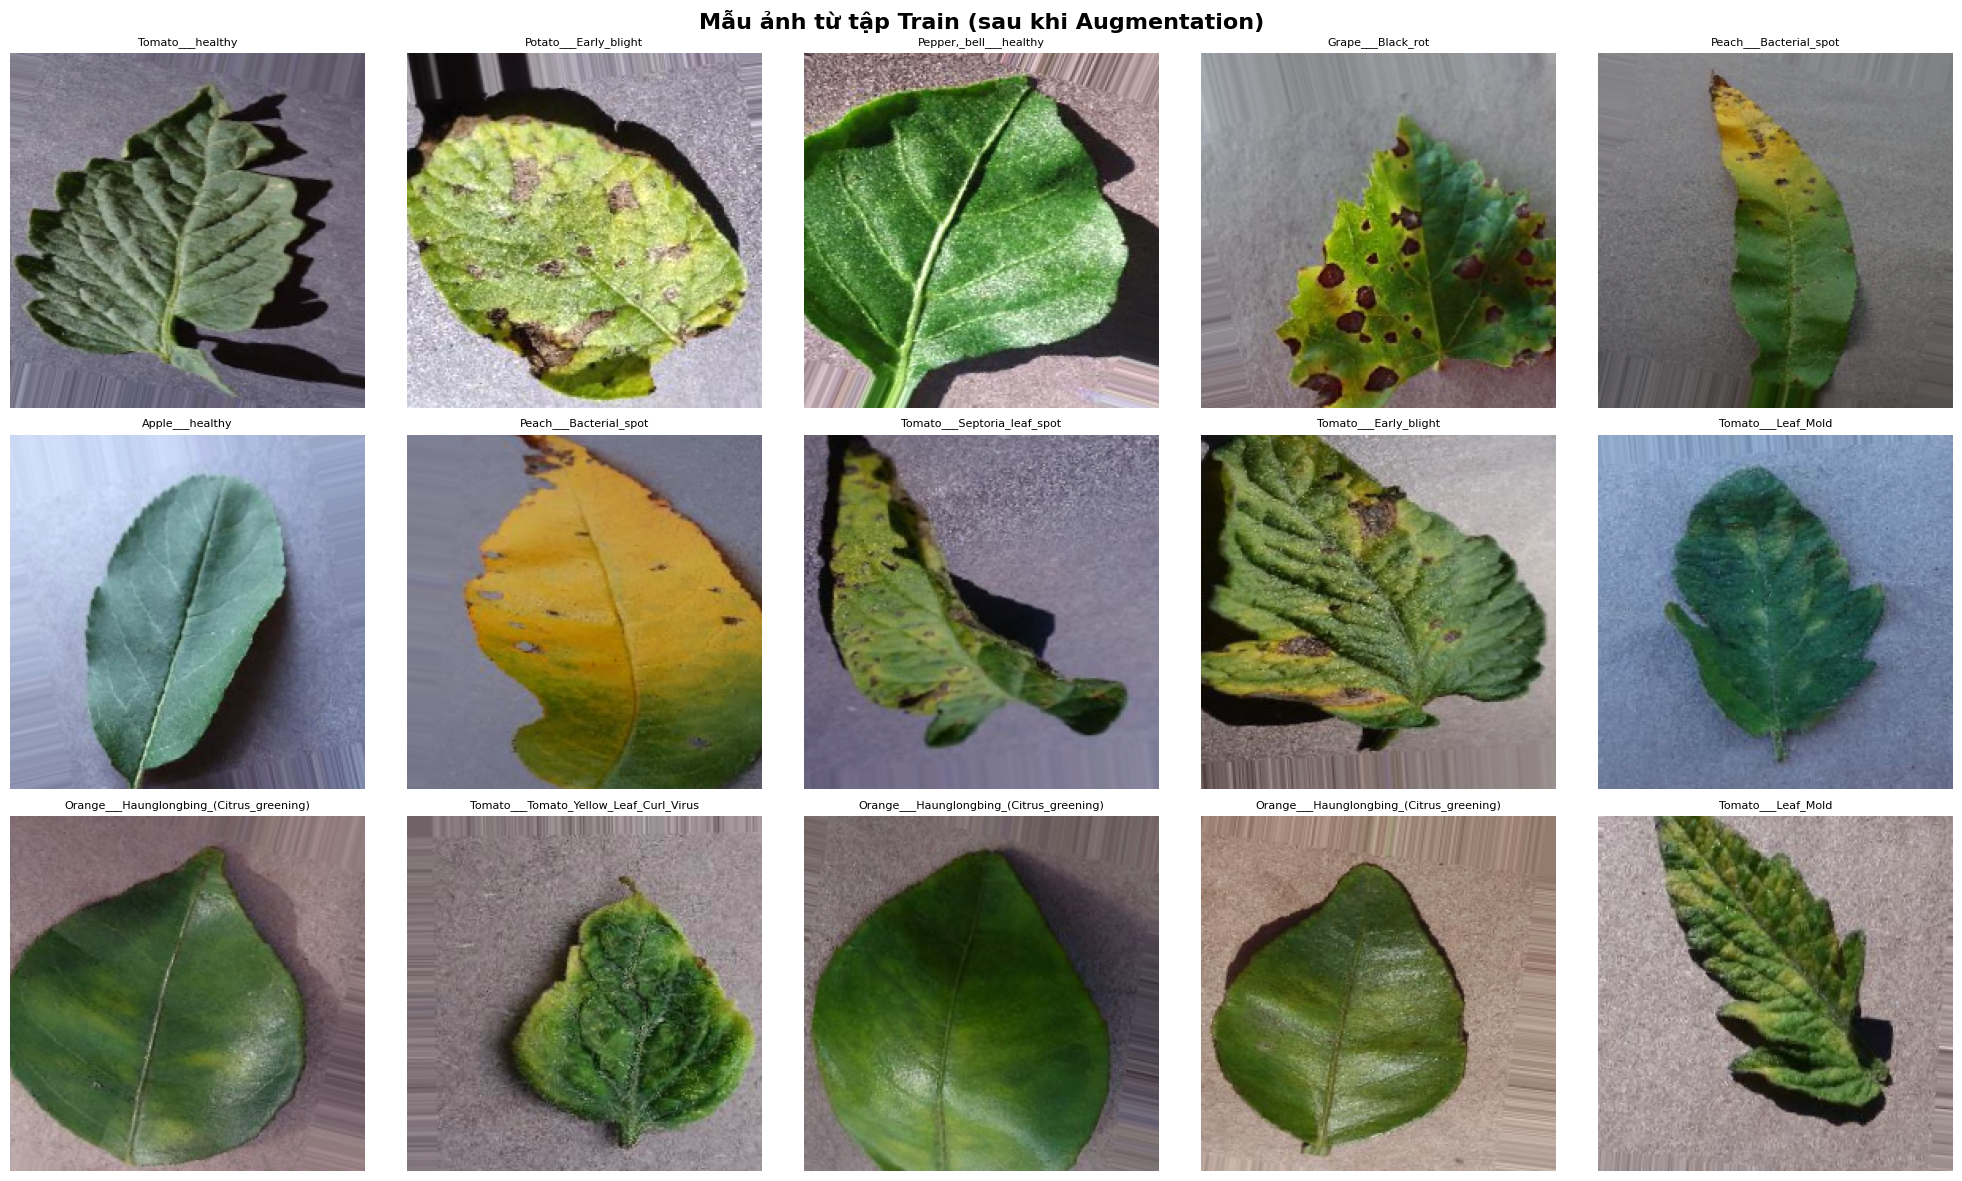

In [21]:

train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

train_gen = train_datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=True, batch_size=BATCH_SIZE, seed=SEED
)

val_gen = val_test_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=False, batch_size=BATCH_SIZE
)

test_gen = val_test_datagen.flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=False, batch_size=BATCH_SIZE
)

CLASS_INDICES = train_gen.class_indices
IDX_TO_CLASS = {v: k for k, v in CLASS_INDICES.items()}

def show_sample_images(gen, n_rows=3, n_cols=5):

    images, labels = next(gen)
    classes = list(gen.class_indices.keys())

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 12))
    fig.suptitle('Mẫu ảnh từ tập Train (sau khi Augmentation)', fontsize=16, fontweight='bold')

    for i, ax in enumerate(axes.flat):
        if i >= len(images):
            ax.axis('off')
            continue
        img = (images[i] + 1) / 2.0
        ax.imshow(img)
        ax.set_title(classes[np.argmax(labels[i])], fontsize=8)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

show_sample_images(train_gen)

---
## Xây dựng mô hình Transfer Learning (MobileNetV2)

In [22]:
base_model = MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)

base_model.trainable = False
print(f"Số lớp trong base model: {len(base_model.layers)}")
print(f"Trọng số đóng băng: {len(base_model.layers)} lớp")

inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)

x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)  # Dropout 40%: ngẫu nhiên tắt 40% neuron khi train

outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = keras.Model(inputs, outputs, name='PlantDisease_MobileNetV2')


model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Số lớp trong base model: 155
Trọng số đóng băng: 155 lớp


Model: "PlantDisease_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,596,710 (9.91 MB)

 Trainable params: 338,214 (1.29 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

---
##Huấn luyện mô hình (Phase 1 - Feature Extraction)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss', patience=5,
    restore_best_weights=True, verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5,
    patience=3, min_lr=1e-7, verbose=1
)
checkpoint = ModelCheckpoint(
    'best_plant_disease_model.h5',
    monitor='val_accuracy', save_best_only=True,
    mode='max', verbose=1
)

callbacks = [early_stop, reduce_lr, checkpoint]

print("Bắt đầu huấn luyện Phase 1 (Feature Extraction)...")
print(f"   Epochs: {EPOCHS} | Batch size: {BATCH_SIZE}")
print("-" * 60)

history_phase1 = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

print("\nHoàn thành Phase 1!")

Bắt đầu huấn luyện Phase 1 (Feature Extraction)...
   Epochs: 10 | Batch size: 32
------------------------------------------------------------
Epoch 1/10
 129/1188 ━━━━━━━━━━━━━━━━━━━━ 7:59 453ms/step - accuracy: 0.5095 - loss: 2.0125

---
##Fine-tuning (Phase 2 - Mở khóa một phần base model)

In [ ]:
base_model.trainable = True

fine_tune_from = int(len(base_model.layers) * 0.7)
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

trainable_count = sum(1 for l in base_model.layers if l.trainable)
print(f"Số lớp được mở khóa để fine-tune: {trainable_count}/{len(base_model.layers)}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

FINE_TUNE_EPOCHS = 5
total_epochs = EPOCHS + FINE_TUNE_EPOCHS

print("\nFine-tuning Phase 2...")
print(f"   Fine-tune thêm {FINE_TUNE_EPOCHS} epochs với LR = 1e-5")
print("-" * 60)

history_phase2 = model.fit(
    train_gen,
    epochs=total_epochs,
    initial_epoch=len(history_phase1.history['loss']),
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

print("\nHoàn thành Fine-tuning!")

---
##  Đồ thị huấn luyện

In [ ]:

def plot_training_history(hist1, hist2=None):

    if hist2 is not None:
        tr_acc  = hist1.history['accuracy']     + hist2.history['accuracy']
        tr_loss = hist1.history['loss']         + hist2.history['loss']
        vl_acc  = hist1.history['val_accuracy'] + hist2.history['val_accuracy']
        vl_loss = hist1.history['val_loss']     + hist2.history['val_loss']
        fine_tune_start = len(hist1.history['loss'])  # Dấu ranh giới 2 phase
    else:
        tr_acc  = hist1.history['accuracy']
        tr_loss = hist1.history['loss']
        vl_acc  = hist1.history['val_accuracy']
        vl_loss = hist1.history['val_loss']
        fine_tune_start = None

    epochs_range = range(1, len(tr_acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle('Lịch sử Huấn luyện Mô hình', fontsize=16, fontweight='bold')


    ax = axes[0]
    ax.plot(epochs_range, tr_acc, 'royalblue', label='Train Accuracy', linewidth=2)
    ax.plot(epochs_range, vl_acc, 'darkorange', label='Validation Accuracy', linewidth=2)
    if fine_tune_start:
        ax.axvline(x=fine_tune_start, color='red', linestyle='--', label='Bắt đầu Fine-tune')
    best_epoch = np.argmax(vl_acc) + 1
    ax.scatter(best_epoch, max(vl_acc), s=150, color='green', zorder=5,
               label=f'Best Epoch = {best_epoch} ({max(vl_acc)*100:.2f}%)')
    ax.set_title('Accuracy qua các Epoch', fontsize=13)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    ax.plot(epochs_range, tr_loss, 'royalblue', label='Train Loss', linewidth=2)
    ax.plot(epochs_range, vl_loss, 'darkorange', label='Validation Loss', linewidth=2)
    if fine_tune_start:
        ax.axvline(x=fine_tune_start, color='red', linestyle='--', label='Bắt đầu Fine-tune')
    best_epoch_loss = np.argmin(vl_loss) + 1
    ax.scatter(best_epoch_loss, min(vl_loss), s=150, color='green', zorder=5,
               label=f'Best Epoch = {best_epoch_loss} (Loss = {min(vl_loss):.4f})')
    ax.set_title('Loss qua các Epoch', fontsize=13)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(" Đã lưu đồ thị: training_history.png")


plot_training_history(history_phase1, history_phase2)

---
##Đánh giá mô hình trên tập Test

In [ ]:

print("Load mô hình tốt nhất từ checkpoint...")
model = keras.models.load_model('best_plant_disease_model.h5')

print("\n" + "="*60)
print("KẾT QUẢ ĐÁNH GIÁ ")
print("="*60)

train_loss, train_acc = model.evaluate(train_gen, verbose=0)
val_loss,   val_acc   = model.evaluate(val_gen,   verbose=0)
test_loss,  test_acc  = model.evaluate(test_gen,  verbose=0)

print(f"Train      — Loss: {train_loss:.4f} | Accuracy: {train_acc*100:.2f}%")
print(f"Validation — Loss: {val_loss:.4f}   | Accuracy: {val_acc*100:.2f}%")
print(f"Test       — Loss: {test_loss:.4f}   | Accuracy: {test_acc*100:.2f}%")

test_gen.reset()
y_pred_probs = model.predict(test_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes

print(f"\nDự đoán xong {len(y_pred)} mẫu test.")

##Confusion Matrix

In [ ]:
cm = confusion_matrix(y_true, y_pred)

# Chuẩn hóa confusion matrix (normalize) để dễ so sánh
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(30, 14))
fig.suptitle('Confusion Matrix - Phân loại Bệnh Lá Cây', fontsize=18, fontweight='bold')

# --- Confusion Matrix gốc (số lượng tuyệt đối) ---
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], linewidths=0.5)
axes[0].set_title('Confusion Matrix (Số lượng)', fontsize=14)
axes[0].set_xlabel('Nhãn dự đoán', fontsize=12)
axes[0].set_ylabel('Nhãn thật', fontsize=12)
axes[0].tick_params(axis='x', rotation=45, labelsize=7)
axes[0].tick_params(axis='y', rotation=0, labelsize=7)

# --- Confusion Matrix chuẩn hóa (tỷ lệ) ---
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], linewidths=0.5)
axes[1].set_title('Confusion Matrix (Tỷ lệ - Normalized)', fontsize=14)
axes[1].set_xlabel('Nhãn dự đoán', fontsize=12)
axes[1].set_ylabel('Nhãn thật', fontsize=12)
axes[1].tick_params(axis='x', rotation=45, labelsize=7)
axes[1].tick_params(axis='y', rotation=0, labelsize=7)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Đã lưu: confusion_matrix.png")

---
##Classification Report

In [ ]:
print("\n" + "="*80)
print("CLASSIFICATION REPORT - BÁO CÁO CHI TIẾT TỪNG LỚP BỆNH")
print("="*80)
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)

# Top 5 lớp bị nhầm lẫn nhiều nhất
print("\n" + "="*80)
print("TOP 5 LỚP BỊ DỰ ĐOÁN SAI NHIỀU NHẤT")
print("="*80)
per_class_acc = cm.diagonal() / cm.sum(axis=1)
worst_classes = np.argsort(per_class_acc)[:5]

for idx in worst_classes:
    class_name = CLASS_NAMES[idx]
    accuracy   = per_class_acc[idx] * 100
    total      = cm.sum(axis=1)[idx]
    correct    = cm[idx, idx]
    print(f"  {class_name:<45} Accuracy: {accuracy:5.1f}% ({correct}/{total} mẫu đúng)")

---
## Lưu mô hình và thông tin lớp

In [ ]:
import json

model_save_path = f'plant_disease_mobilenetv2_acc{test_acc*100:.1f}.h5'
model.save(model_save_path)
print(f"Đã lưu mô hình: {model_save_path}")

class_info = {
    'class_indices': CLASS_INDICES,
    'idx_to_class':  {str(k): v for k, v in IDX_TO_CLASS.items()},
    'num_classes':   NUM_CLASSES,
    'img_size':      list(IMG_SIZE),
    'model_name':    'MobileNetV2',
    'test_accuracy': float(test_acc)
}

with open('class_info.json', 'w', encoding='utf-8') as f:
    json.dump(class_info, f, ensure_ascii=False, indent=2)

print("Đã lưu thông tin lớp: class_info.json")
print(f"\nTÓM TẮT:")
print(f"   Mô hình: MobileNetV2 + Transfer Learning")
print(f"   Số lớp:  {NUM_CLASSES} loại bệnh")
print(f"   Test Accuracy: {test_acc*100:.2f}%")

---
##  Demo Web UI với Gradio

> **Hướng dẫn:** Chạy cell này để khởi động giao diện web demo. Gradio sẽ tạo một link `localhost` (và optionally một link public). Mở link đó trên trình duyệt để upload ảnh lá cây và xem kết quả chẩn đoán bệnh!

In [ ]:
import gradio as gr
import json

with open('class_info.json', 'r', encoding='utf-8') as f:
    class_info = json.load(f)

IDX_TO_CLASS_DEMO = class_info['idx_to_class']
IMG_SIZE_DEMO = tuple(class_info['img_size'])



def predict_disease(image):

    if image is None:
        return {"Lỗi": 1.0}
    img = image.resize(IMG_SIZE_DEMO)

    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)[0]

    top5_indices = np.argsort(predictions)[::-1][:5]
    results = {}
    for idx in top5_indices:
        class_name = IDX_TO_CLASS_DEMO[str(idx)]

        class_name_display = class_name.replace('_', ' ')
        results[class_name_display] = float(predictions[idx])

    return results

with gr.Blocks(
    title="Chẩn đoán Bệnh Lá Cây",
    theme=gr.themes.Soft()
) as demo:

    gr.Markdown("""
    # Hệ thống Chẩn đoán Bệnh Lá Cây
    ### Sử dụng Transfer Learning với MobileNetV2
    **Hướng dẫn:** Upload ảnh lá cây → Nhấn "Phân tích" → Xem kết quả chẩn đoán
    """)

    with gr.Row():
        with gr.Column(scale=1):
            input_image = gr.Image(
                type="pil",
                label="Upload ảnh lá cây",
                height=350
            )
            submit_btn = gr.Button(
                " Phân tích Bệnh",
                variant="primary",
                size="lg"
            )
        with gr.Column(scale=1):
            output_label = gr.Label(
                label="Kết quả chẩn đoán (Top-5)",
                num_top_classes=5
            )

    gr.Markdown("### Thông tin mô hình")
    gr.Markdown(f"""
    - **Kiến trúc:** MobileNetV2 + Transfer Learning
    - **Tập dữ liệu:** PlantVillage Dataset
    - **Số lớp bệnh:** {NUM_CLASSES} lớp
    - **Test Accuracy:** {class_info['test_accuracy']*100:.2f}%
    - **Kích thước ảnh đầu vào:** 224 × 224 pixels
    """)

    submit_btn.click(
        fn=predict_disease,
        inputs=input_image,
        outputs=output_label
    )

    input_image.change(
        fn=predict_disease,
        inputs=input_image,
        outputs=output_label
    )

demo.launch(
    share=True,
    server_port=7860,
    show_error=True
)

---
## 📝 Kết luận

### Tóm tắt giải pháp
| Thành phần | Chi tiết |
|---|---|
| **Mô hình** | MobileNetV2 (Pre-trained trên ImageNet) |
| **Kỹ thuật** | Transfer Learning + Fine-tuning 2 Phase |
| **Tăng cường dữ liệu** | Flip, Rotation, Zoom, Brightness |
| **Optimizer** | Adam (Phase 1: 1e-3, Phase 2: 1e-5) |
| **Callbacks** | EarlyStopping, ReduceLROnPlateau, ModelCheckpoint |
| **Demo** | Gradio Web UI |

### Lý do MobileNetV2 phù hợp cho ứng dụng thực tế
1. **Kích thước nhỏ:** ~14MB so với ~500MB của VGG16 → dễ tích hợp vào app điện thoại.
2. **Tốc độ nhanh:** Inference trên CPU điện thoại < 200ms → trải nghiệm realtime.
3. **Accuracy cao:** Nhờ Transfer Learning, đạt accuracy tốt dù không cần huấn luyện từ đầu.
4. **Depthwise Separable Convolutions:** Kỹ thuật độc đáo giúp giảm số phép tính mà vẫn giữ được độ chính xác.

### Hướng phát triển
- Xuất mô hình sang **TensorFlow Lite** (`.tflite`) để chạy trực tiếp trên điện thoại Android/iOS.
- Tích hợp vào ứng dụng di động với **Flutter** hoặc **React Native**.
- Thu thập thêm dữ liệu ảnh chụp ngoài đồng thực tế (điều kiện ánh sáng, góc chụp đa dạng hơn).